# 🎧 My Spotify Wrapped: A Personal Listening Data Analysis

*A mini personalized Spotify Wrapped built with Python, Pandas, NumPy and Matplotlib.*

In this project, we explored our own Spotify listening history, uncovered our listening statistics, and found out which songs, artists and albums we had listened to the most. We used Python to turn our Spotify data into a personal music summary and created visualizations to present our findings.

## What we discovered
- Total listening time
- The total number of listening entries in streaming history
- How many unique artists were listened to
- Top 10 songs
- Top 10 artists
- Patterns in the most-played songs through visualizations

## Before we began
1. Requested our **Extended Streaming History** from Spotify (**Link**: www.spotify.com/in-en/account/privacy/)
2. Downloaded and extracted the ZIP archive
3. Converted each listening-history JSON file into a CSV file using an online JSON-to-CSV converter (**Link**: https://data.page/json/csv)
4. Uploaded them in Section 1

**By the end of this project**, we had our own data-driven Spotify Wrapped, built using Python data analytical skills

## 1. Upload the CSV files to Google Colab

Upload all the CSV files converted from the Spotify JSON export.

In [130]:
from google.colab import files

uploaded = files.upload()

Saving StreamingHistory_music_0.csv to StreamingHistory_music_0 (3).csv


## 2. Import the libraries

Import the libraries needed for data analysis and visualization.

In [131]:
# Importing the required libraries
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 3. Read the CSV file(s)

Read the uploaded CSV file into a DataFrame.

In [132]:
# Reading CSV file into a DataFrame
df = pd.read_csv("StreamingHistory_music_0.csv")

## 4. Explore the dataset

Look at
1. the first five rows.
2. the number of rows and columns.
3. the column names.
4. the data types and non-null values.
5. summary statistics where appropriate.

In [133]:
# First five rows
display(df.head())

# Number of rows and columns
print(f"Dimensions(rows, columns): {df.shape}")

# Column names
print(f"Columns in dataset: {df.columns}")

# Dataset information
display(df.info())

# Summary statistics
display(df.describe())

,endTime,artistName,trackName,msPlayed
0,2025-11-18 14:10,*NSYNC,Bye Bye Bye,149211
1,2025-11-19 14:17,Vanessa Carlton,A Thousand Miles,2162
2,2025-11-19 14:17,Michael Bublé,Feeling Good,3719
3,2025-11-19 14:17,*NSYNC,Bye Bye Bye,2846
4,2025-11-19 14:17,Maroon 5,She Will Be Loved - Radio Mix,1831


Dimensions(rows, columns): (5504, 4)
Columns in dataset: Index(['endTime', 'artistName', 'trackName', 'msPlayed'], dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5504 entries, 0 to 5503
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   endTime     5504 non-null   object
 1   artistName  5504 non-null   object
 2   trackName   5504 non-null   object
 3   msPlayed    5504 non-null   int64 
dtypes: int64(1), object(3)
memory usage: 172.1+ KB


None

,msPlayed
count,5504.000000
mean,149894.281250
std,94471.983751
min,0.000000
25%,63981.250000
50%,169135.000000
75%,216320.000000
max,501057.000000


## 5. Clean the data

Remove information that is not needed and keep valid music records.

This includes:
1. Checking for missing values.
2. Removing columns not needed for this analysis


In [134]:
# Number of missing values per column
print(f"Number of missing values / column:")
display(df.isnull().sum())

# Number of exact duplicate rows
print(f"Number of exact duplicate rows: {df.duplicated().sum()}")

# Keeping valid music listening records with track and artist names
df = df.dropna()
df = df.drop_duplicates()

# Cleaned dataset
display(df)

Number of missing values / column:


,0
endTime,0
artistName,0
trackName,0
msPlayed,0


Number of exact duplicate rows: 0


,endTime,artistName,trackName,msPlayed
0,2025-11-18 14:10,*NSYNC,Bye Bye Bye,149211
1,2025-11-19 14:17,Vanessa Carlton,A Thousand Miles,2162
2,2025-11-19 14:17,Michael Bublé,Feeling Good,3719
3,2025-11-19 14:17,*NSYNC,Bye Bye Bye,2846
4,2025-11-19 14:17,Maroon 5,She Will Be Loved - Radio Mix,1831
...,...,...,...,...
5499,2026-11-18 14:34,Keane,Somewhere Only We Know,237146
5500,2026-11-18 14:38,M83,Midnight City,243960
5501,2026-11-18 14:42,NEIKED,Glide,184405
5502,2026-11-18 14:54,Ravyn Lenae,Love Me Not,213466


## 6. Your total listening time

Calculate the total time represented by the `msPlayed` column

(**Note:-**
This is the recorded playback time in your export. It may include partial plays.)

In [135]:
# Total listening time in milliseconds
played_ms = df["msPlayed"].sum()

# Converting milliseconds into hours and hours into days
played_hrs = (played_ms / (1000*60*60))
played_days = round((played_hrs / 24))

# Display the total listening time
print(f"Listened for {played_hrs} hours")
print(f"That's almost {played_days} days of listening to music non-stop!")

Listened for 229.1717011111111 hours
That's almost 10 days of listening to music non-stop!


## 7. Total number of streams

Find the total number of listening-history entries in your cleaned dataset.



In [136]:
# Display the total number of streams / entries
print(f"{len(df)} streaming records found")

5504 streaming records found


## 8. Total number of artists listened to

Find how many different artists appear in your listening history.

**Note:** Collaborations are not grouped with separate artists and are considered as individual entries


In [137]:
# Cleaning again - removing non-artist rows
df = df[df["artistName"] != "Brainy"]

# Count the number of unique artists
unq_artists = df["artistName"].nunique()

# Display the total number of artists
print(f"Listened to {unq_artists} artists")
print(f"(Note: Collaborations are counted as separate artist entries)")

Listened to 803 artists
(Note: Collaborations are counted as separate artist entries)


## 9. Your top 10 songs

Find the 10 songs with the highest number of listening-history entries.

In [138]:
# Group by track name and artist name, count the entries, sort in order from most entries to least, and select the top 10
top_songs = df.groupby(["trackName", "artistName"]).size().sort_values(ascending=False).head(10)

# Display your top 10 songs
print(f"Most listened to songs are:")
display(top_songs)

Most listened to songs are:


,,0
trackName,artistName,
Hymn for the Weekend,Coldplay,34
Something Just Like This,The Chainsmokers,28
Demons,Imagine Dragons,27
Unity,The Walkers,27
The Nights,Avicii,26
Hero,Alan Walker,26
Faded,Alan Walker,26
Don't Let Me Down,The Chainsmokers,26
Bad Habits,Ed Sheeran,24


## 10. Your top 10 artists

Find the 10 artists with the highest number of listening-history entries.

In [139]:
# Count listening-history entries for each artist and select top 10
top_artists = df["artistName"].value_counts().head(10)

# Display your top 10 artists
print(f"Top artists:")
display(top_artists)

Top artists:


,count
artistName,
Alan Walker,336
Coldplay,140
Pritam,132
Imagine Dragons,101
Sia,96
Ed Sheeran,87
The Chainsmokers,81
Avicii,62
David Guetta,62


# 11. Visualizing your Spotify Wrapped

Create visualizations.

(Each graph uses a different chart type.)

### 11A. Top 10 songs

Create a bar chart showing the 10 songs listened to most often.

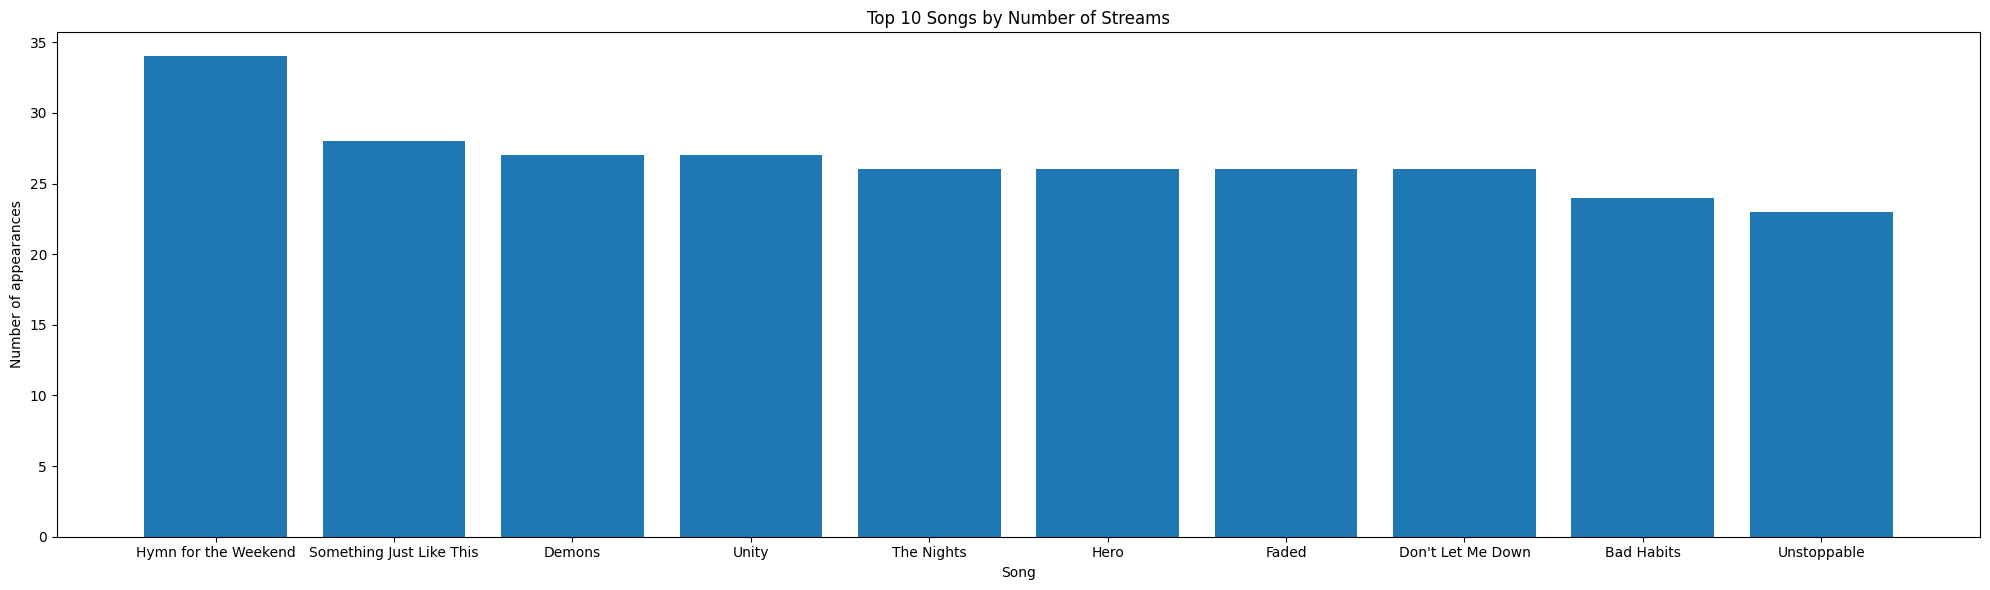

In [140]:
# Create a figure
plt.figure(figsize=(20, 6))

# Create a bar chart for your top 10 songs
song_labels = [song for song, artist in top_songs.index]
plt.bar(song_labels, top_songs.values)

# Add a title and axis labels
plt.title("Top 10 Songs by Number of Streams")
plt.xlabel("Song")
plt.ylabel("Number of appearances")

# Display the graph
plt.tight_layout()
plt.show()

### 11B. Graph 2 — Top 10 artists (Horizontal bar chart)

**Your task:** Create a horizontal bar chart showing your 10 most-listened-to artists.

**Hints:**
- Use the top 10 artists result from Section 11.
- Use `plt.barh()`.
- Put artist names on the y-axis and number of entries on the x-axis.
- Add a title and axis labels.

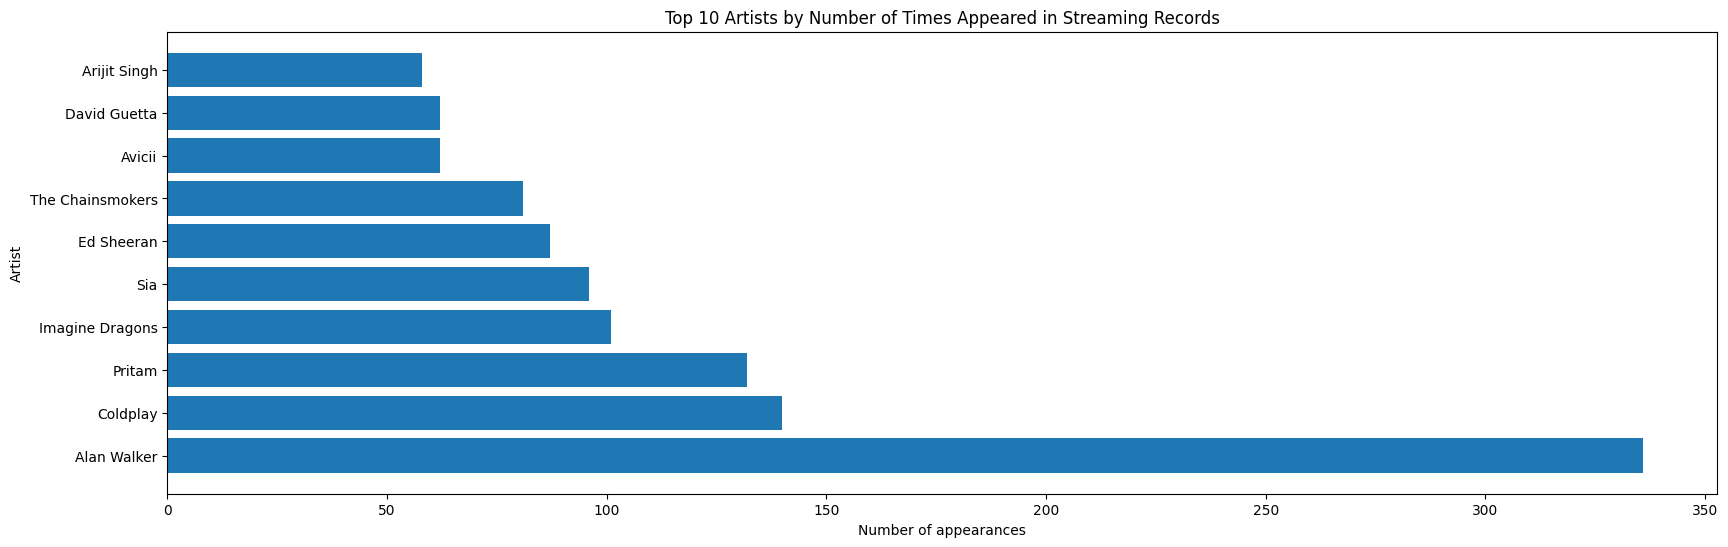

In [141]:
# Create a figure
plt.figure(figsize = (20,6))

# Create a horizontal bar chart for your top 10 artists
artist_name = [artist for artist in top_artists.index]
plt.barh(artist_name, top_artists.values)

# Add a title and axis labels
plt.title("Top 10 Artists by Number of Times Appeared in Streaming Records")
plt.xlabel("Number of appearances")
plt.ylabel("Artist")

# Display the graph
plt.show()